<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter7/ballistic_2d_jump_simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

True 2D Ballistic Jumping Bug Simulation

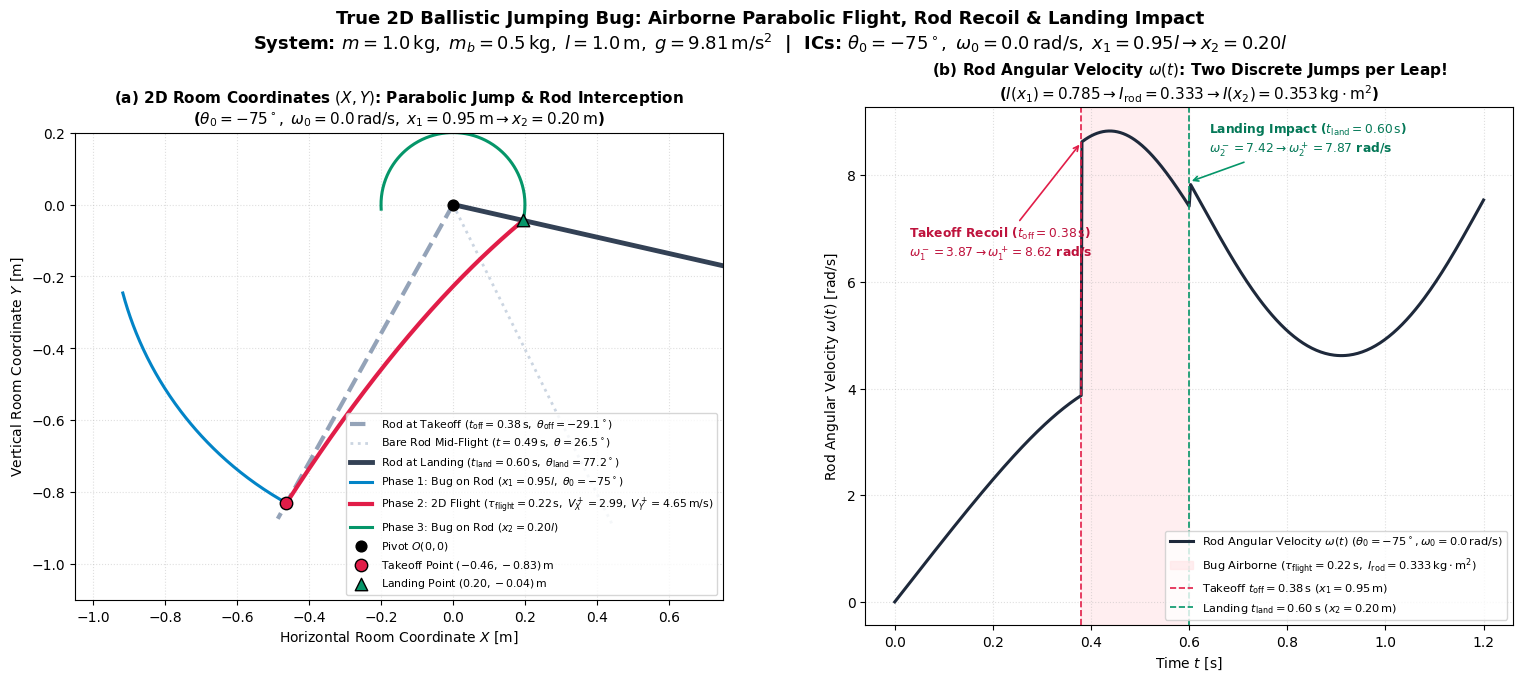

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# =============================================================================
# 1. SYSTEM PARAMETERS & BARE/LOADED ROD DYNAMICS
# =============================================================================
m = 1.0       # Rod mass (kg)
m_b = 0.5     # Bug mass (kg)
l = 1.0       # Rod length (m)
g = 9.81      # Gravity (m/s^2)
I_rod = (1.0 / 3.0) * m * l**2
kappa_rod = 0.5 * m * g * l

def I_loaded(x):
    return I_rod + m_b * x**2

def kappa_loaded(x):
    return kappa_rod + m_b * g * x

def ode_loaded(t, state, x_bug):
    th, om = state
    return [om, -(kappa_loaded(x_bug) / I_loaded(x_bug)) * np.sin(th)]

def ode_bare_rod(t, state):
    th, om = state
    return [om, -(kappa_rod / I_rod) * np.sin(th)]

# =============================================================================
# 2. SIMULATE A TRUE 2D BALLISTIC JUMP (WITH TAKEOFF RECOIL & LANDING IMPACT)
# =============================================================================
def simulate_2d_ballistic_jump(theta0=-np.radians(75.0), omega0=0.0, x1=0.95*l, x2=0.20*l,
                               t_takeoff=0.38, tau_flight=0.22, t_total=1.20):
    # --- PHASE 1: Bug riding on the rod at x1 (0 <= t <= t_takeoff) ---
    t1 = np.linspace(0.0, t_takeoff, 150)
    sol1 = solve_ivp(ode_loaded, [0.0, t_takeoff], [theta0, omega0], t_eval=t1, args=(x1,), rtol=1e-10, atol=1e-10)
    th1, om1 = sol1.y[0], sol1.y[1]

    # State just before takeoff
    th_off = th1[-1]
    om_off_minus = om1[-1]
    X_start = x1 * np.sin(th_off)
    Y_start = -x1 * np.cos(th_off)

    # --- SOLVE THE 2D INTERCEPTION PROBLEM (SELF-CONSISTENT SHOOTING) ---
    om_off_plus = om_off_minus
    for _ in range(8):
        sol_air_pred = solve_ivp(ode_bare_rod, [0.0, tau_flight], [th_off, om_off_plus], rtol=1e-10, atol=1e-10)
        th_land_pred = sol_air_pred.y[0, -1]
        X_target = x2 * np.sin(th_land_pred)
        Y_target = -x2 * np.cos(th_land_pred)

        # Required 2D ballistic launch velocity in room coordinates (X, Y)
        Vx_plus = (X_target - X_start) / tau_flight
        Vy_plus = (Y_target - Y_start) / tau_flight + 0.5 * g * tau_flight

        # Transverse velocity component v_{b,theta}^+ = Vx^+ cos(th_off) + Vy^+ sin(th_off)
        v_theta_plus = Vx_plus * np.cos(th_off) + Vy_plus * np.sin(th_off)

        # Exact angular momentum conservation at takeoff gives rod recoil:
        om_off_plus = om_off_minus - (m_b * x1 / I_rod) * (v_theta_plus - x1 * om_off_minus)

    # --- PHASE 2: Airborne Ballistic Flight (t_takeoff < t <= t_land) ---
    t_land = t_takeoff + tau_flight
    t2 = np.linspace(t_takeoff, t_land, 150)
    tau_arr = t2 - t_takeoff
    sol2 = solve_ivp(ode_bare_rod, [t_takeoff, t_land], [th_off, om_off_plus], t_eval=t2, rtol=1e-10, atol=1e-10)
    th2, om2 = sol2.y[0], sol2.y[1]

    # Bug's 2D parabolic trajectory in room coordinates
    Xb_air = X_start + Vx_plus * tau_arr
    Yb_air = Y_start + Vy_plus * tau_arr - 0.5 * g * tau_arr**2

    # --- STAGE 4: Landing Impact at t = t_land ---
    th_land = th2[-1]
    om_land_minus = om2[-1]
    Vx_minus = Vx_plus
    Vy_minus = Vy_plus - g * tau_flight
    X_end, Y_end = Xb_air[-1], Yb_air[-1]

    # Exact angular momentum conservation about pivot at landing:
    L_bug_land = m_b * (X_end * Vy_minus - Y_end * Vx_minus)
    om_land_plus = (I_rod * om_land_minus + L_bug_land) / I_loaded(x2)

    # --- PHASE 3: Bug riding on the rod at x2 (t_land < t <= t_total) ---
    t3 = np.linspace(t_land, t_total, 200)
    sol3 = solve_ivp(ode_loaded, [t_land, t_total], [th_land, om_land_plus], t_eval=t3, args=(x2,), rtol=1e-10, atol=1e-10)
    th3, om3 = sol3.y[0], sol3.y[1]

    # Assemble full history
    t_all = np.concatenate([t1, t2[1:], t3[1:]])
    th_all = np.concatenate([th1, th2[1:], th3[1:]])
    om_all = np.concatenate([om1, om2[1:], om3[1:]])

    Xb_all = np.concatenate([x1 * np.sin(th1), Xb_air[1:], x2 * np.sin(th3[1:])])
    Yb_all = np.concatenate([-x1 * np.cos(th1), Yb_air[1:], -x2 * np.cos(th3[1:])])

    return (t_all, th_all, om_all, Xb_all, Yb_all,
            (X_start, Y_start, th_off, om_off_minus, om_off_plus, Vx_plus, Vy_plus),
            (X_end, Y_end, th_land, om_land_minus, om_land_plus, Vx_minus, Vy_minus),
            (Xb_air, Yb_air, th2),
            (theta0, omega0, x1, x2, t_takeoff, tau_flight, t_land))

# =============================================================================
# 3. RUN SIMULATION AND PLOT 2-PANEL VISUALIZATION WITH FULL PARAMETERS
# =============================================================================
(t_all, th_all, om_all, Xb_all, Yb_all,
 takeoff_info, land_info, air_info, params_info) = simulate_2d_ballistic_jump()

X_start, Y_start, th_off, om_off_m, om_off_p, Vx_p, Vy_p = takeoff_info
X_end, Y_end, th_land, om_land_m, om_land_p, Vx_m, Vy_m = land_info
Xb_air, Yb_air, th2 = air_info
theta0, omega0, x1, x2, t_off, tau_f, t_land = params_info

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.8, 7.0))
fig.suptitle(
    f"True 2D Ballistic Jumping Bug: Airborne Parabolic Flight, Rod Recoil & Landing Impact\n"
    f"System: $m={m:.1f}\\,\\mathrm{{kg}},\\; m_b={m_b:.1f}\\,\\mathrm{{kg}},\\; l={l:.1f}\\,\\mathrm{{m}},\\; g={g:.2f}\\,\\mathrm{{m/s^2}}$  |  "
    f"ICs: $\\theta_0={np.degrees(theta0):.0f}^\\circ,\\; \\omega_0={omega0:.1f}\\,\\mathrm{{rad/s}},\\; x_1={x1/l:.2f}l \\to x_2={x2/l:.2f}l$",
    fontsize=13.0, fontweight="bold", y=0.98
)

# --- Panel (a): 2D Room Space (X, Y) Trajectory ---
th_mid = th2[len(th2)//2]
ax1.plot([0, l*np.sin(th_off)], [0, -l*np.cos(th_off)], color="#94a3b8", lw=3.0, ls="--",
         label=f"Rod at Takeoff ($t_{{\\mathrm{{off}}}}={t_off:.2f}\\,\\mathrm{{s}},\\; \\theta_{{\\mathrm{{off}}}}={np.degrees(th_off):.1f}^\\circ$)")
ax1.plot([0, l*np.sin(th_mid)], [0, -l*np.cos(th_mid)], color="#cbd5e1", lw=2.0, ls=":",
         label=f"Bare Rod Mid-Flight ($t={t_off + 0.5*tau_f:.2f}\\,\\mathrm{{s}},\\; \\theta={np.degrees(th_mid):.1f}^\\circ$)")
ax1.plot([0, l*np.sin(th_land)], [0, -l*np.cos(th_land)], color="#334155", lw=3.5,
         label=f"Rod at Landing ($t_{{\\mathrm{{land}}}}={t_land:.2f}\\,\\mathrm{{s}},\\; \\theta_{{\\mathrm{{land}}}}={np.degrees(th_land):.1f}^\\circ$)")

# Plot bug's path on rod before takeoff, parabolic arc in air, and path after landing
ax1.plot(Xb_all[:150], Yb_all[:150], color="#0284c7", lw=2.2,
         label=f"Phase 1: Bug on Rod ($x_1 = {x1/l:.2f}l,\\; \\theta_0 = {np.degrees(theta0):.0f}^\\circ$)")
ax1.plot(Xb_air, Yb_air, color="#e11d48", lw=3.0,
         label=f"Phase 2: 2D Flight ($\\tau_{{\\mathrm{{flight}}}}={tau_f:.2f}\\,\\mathrm{{s}},\\; V_X^+={Vx_p:.2f},\\; V_Y^+={Vy_p:.2f}\\,\\mathrm{{m/s}}$)")
ax1.plot(Xb_all[299:], Yb_all[299:], color="#059669", lw=2.2,
         label=f"Phase 3: Bug on Rod ($x_2 = {x2/l:.2f}l$)")

ax1.scatter([0], [0], color="k", s=60, zorder=6, label="Pivot $O(0,0)$")
ax1.scatter([X_start], [Y_start], color="#e11d48", edgecolor="k", s=80, zorder=7,
            label=f"Takeoff Point $({X_start:.2f}, {Y_start:.2f})\\,\\mathrm{{m}}$")
ax1.scatter([X_end], [Y_end], color="#059669", edgecolor="k", s=80, marker="^", zorder=7,
            label=f"Landing Point $({X_end:.2f}, {Y_end:.2f})\\,\\mathrm{{m}}$")

ax1.set_title(
    f"(a) 2D Room Coordinates $(X, Y)$: Parabolic Jump & Rod Interception\n"
    f"($\\theta_0 = {np.degrees(theta0):.0f}^\\circ,\\; \\omega_0 = {omega0:.1f}\\,\\mathrm{{rad/s}},\\; x_1={x1:.2f}\\,\\mathrm{{m}} \\to x_2={x2:.2f}\\,\\mathrm{{m}}$)",
    fontsize=11.0, fontweight="bold"
)
ax1.set_xlabel("Horizontal Room Coordinate $X$ [m]", fontsize=10)
ax1.set_ylabel("Vertical Room Coordinate $Y$ [m]", fontsize=10)
ax1.set_aspect("equal")
ax1.set_xlim(-1.05, 0.75)
ax1.set_ylim(-1.10, 0.20)
ax1.grid(True, ls=":", alpha=0.4)
ax1.legend(loc="lower right", fontsize=7.8)

# --- Panel (b): Angular Velocity omega(t) Showing Takeoff Recoil & Landing Spike ---
ax2.plot(t_all, om_all, color="#1e293b", lw=2.2,
         label=f"Rod Angular Velocity $\\omega(t)$ ($\\theta_0={np.degrees(theta0):.0f}^\\circ, \\omega_0={omega0:.1f}\\,\\mathrm{{rad/s}}$)")
ax2.axvspan(t_off, t_land, color="#ffe4e6", alpha=0.6,
            label=f"Bug Airborne ($\\tau_{{\\mathrm{{flight}}}}={tau_f:.2f}\\,\\mathrm{{s}},\\; I_{{\\mathrm{{rod}}}}={I_rod:.3f}\\,\\mathrm{{kg\\cdot m^2}}$)")
ax2.axvline(t_off, color="#e11d48", ls="--", lw=1.2, label=f"Takeoff $t_{{\\mathrm{{off}}}} = {t_off:.2f}\\,\\mathrm{{s}}$ ($x_1={x1:.2f}\\,\\mathrm{{m}}$)")
ax2.axvline(t_land, color="#059669", ls="--", lw=1.2, label=f"Landing $t_{{\\mathrm{{land}}}} = {t_land:.2f}\\,\\mathrm{{s}}$ ($x_2={x2:.2f}\\,\\mathrm{{m}}$)")

ax2.annotate(f"Takeoff Recoil ($t_{{\\mathrm{{off}}}}={t_off:.2f}\\,\\mathrm{{s}}$)\n$\\omega_1^- = {om_off_m:.2f} \\to \\omega_1^+ = {om_off_p:.2f}$ rad/s",
             xy=(t_off, om_off_p), xytext=(0.03, om_off_p - 2.15),
             arrowprops=dict(arrowstyle="->", color="#e11d48", lw=1.2),
             fontsize=8.8, fontweight="bold", color="#be123c")

ax2.annotate(f"Landing Impact ($t_{{\\mathrm{{land}}}}={t_land:.2f}\\,\\mathrm{{s}}$)\n$\\omega_2^- = {om_land_m:.2f} \\to \\omega_2^+ = {om_land_p:.2f}$ rad/s",
             xy=(t_land, om_land_p), xytext=(0.64, om_land_p + 0.55),
             arrowprops=dict(arrowstyle="->", color="#059669", lw=1.2),
             fontsize=8.8, fontweight="bold", color="#047857")

ax2.set_title(
    f"(b) Rod Angular Velocity $\\omega(t)$: Two Discrete Jumps per Leap!\n"
    f"($I(x_1)={I_loaded(x1):.3f} \\to I_{{\\mathrm{{rod}}}}={I_rod:.3f} \\to I(x_2)={I_loaded(x2):.3f}\\,\\mathrm{{kg\\cdot m^2}}$)",
    fontsize=11.0, fontweight="bold"
)
ax2.set_xlabel("Time $t$ [s]", fontsize=10)
ax2.set_ylabel("Rod Angular Velocity $\\omega(t)$ [rad/s]", fontsize=10)
ax2.grid(True, ls=":", alpha=0.4)
ax2.legend(loc="lower right", fontsize=8.2)

plt.subplots_adjust(left=0.06, right=0.97, bottom=0.10, top=0.84, wspace=0.22)
plt.show()